In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt

In [3]:
ruta = '/Users/mateoflores/Documents/Tec/OptimizacionEstocastica/data/ratings.csv'

datos = pd.read_csv(ruta)
datos['date'] = pd.to_datetime(datos['date'], format='%d/%m/%Y')
datos.head(5)

,rating,id_company,date
0,CCC,BMV_001,2019-01-01
1,BB,BMV_001,2019-02-01
2,BB,BMV_001,2019-03-01
3,B,BMV_001,2019-04-01
4,BBB,BMV_001,2019-05-01


In [4]:
frec_calif = datos['rating'].value_counts(normalize=True).reset_index()
frec_calif

,rating,proportion
0,BB,0.357634
1,BBB,0.283356
2,B,0.215956
3,A,0.090784
4,CCC,0.026135
5,AA,0.016506
6,AAA,0.005502
7,CC,0.002751
8,D,0.001376


In [5]:
frec_emisor = datos['id_company'].value_counts(normalize=True).reset_index()
frec_emisor

,id_company,proportion
0,BMV_007,0.185695
1,BMV_005,0.141678
2,BMV_003,0.140303
3,BMV_001,0.126547
4,BMV_002,0.126547
5,BMV_008,0.125172
6,BMV_004,0.110041
7,BMV_006,0.044017


In [6]:
ESCALA = ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC', 'CC', 'C', 'DDD', 'DD', 'D']

# posicion de cada calificacion dentro de la matriz
posiciones = {calif: k for k, calif in enumerate(ESCALA)}


def matrizVacia():
    #     AAA  AA  A  BBB  BB  B  CCC  CC  C  DDD  DD  D
    M = np.zeros((len(ESCALA), len(ESCALA)))
    return M


def posicionDe(calif):
    return posiciones[calif]

In [7]:
def conteoTransiciones(emisor):
    hist = datos[datos['id_company'] == emisor]
    hist = hist.sort_values(by='date')
    M = matrizVacia()
    for k in range(len(hist) - 1):
        desde = hist.iloc[k]['rating']
        hacia = hist.iloc[k + 1]['rating']
        M[posicionDe(desde)][posicionDe(hacia)] += 1
    return M

In [8]:
def normalizaFila(fila):
    total = np.sum(fila)
    for k in range(len(fila)):
        fila[k] = fila[k] / total if total > 0 else fila[k]
    return fila


def normalizaMatriz(M):
    for k in range(M.shape[0]):
        M[k] = normalizaFila(M[k])
    return M

In [9]:
emisores = datos['id_company'].dropna().unique()
matrices = {}

for emisor in emisores:
    matrices[emisor] = normalizaMatriz(conteoTransiciones(emisor))

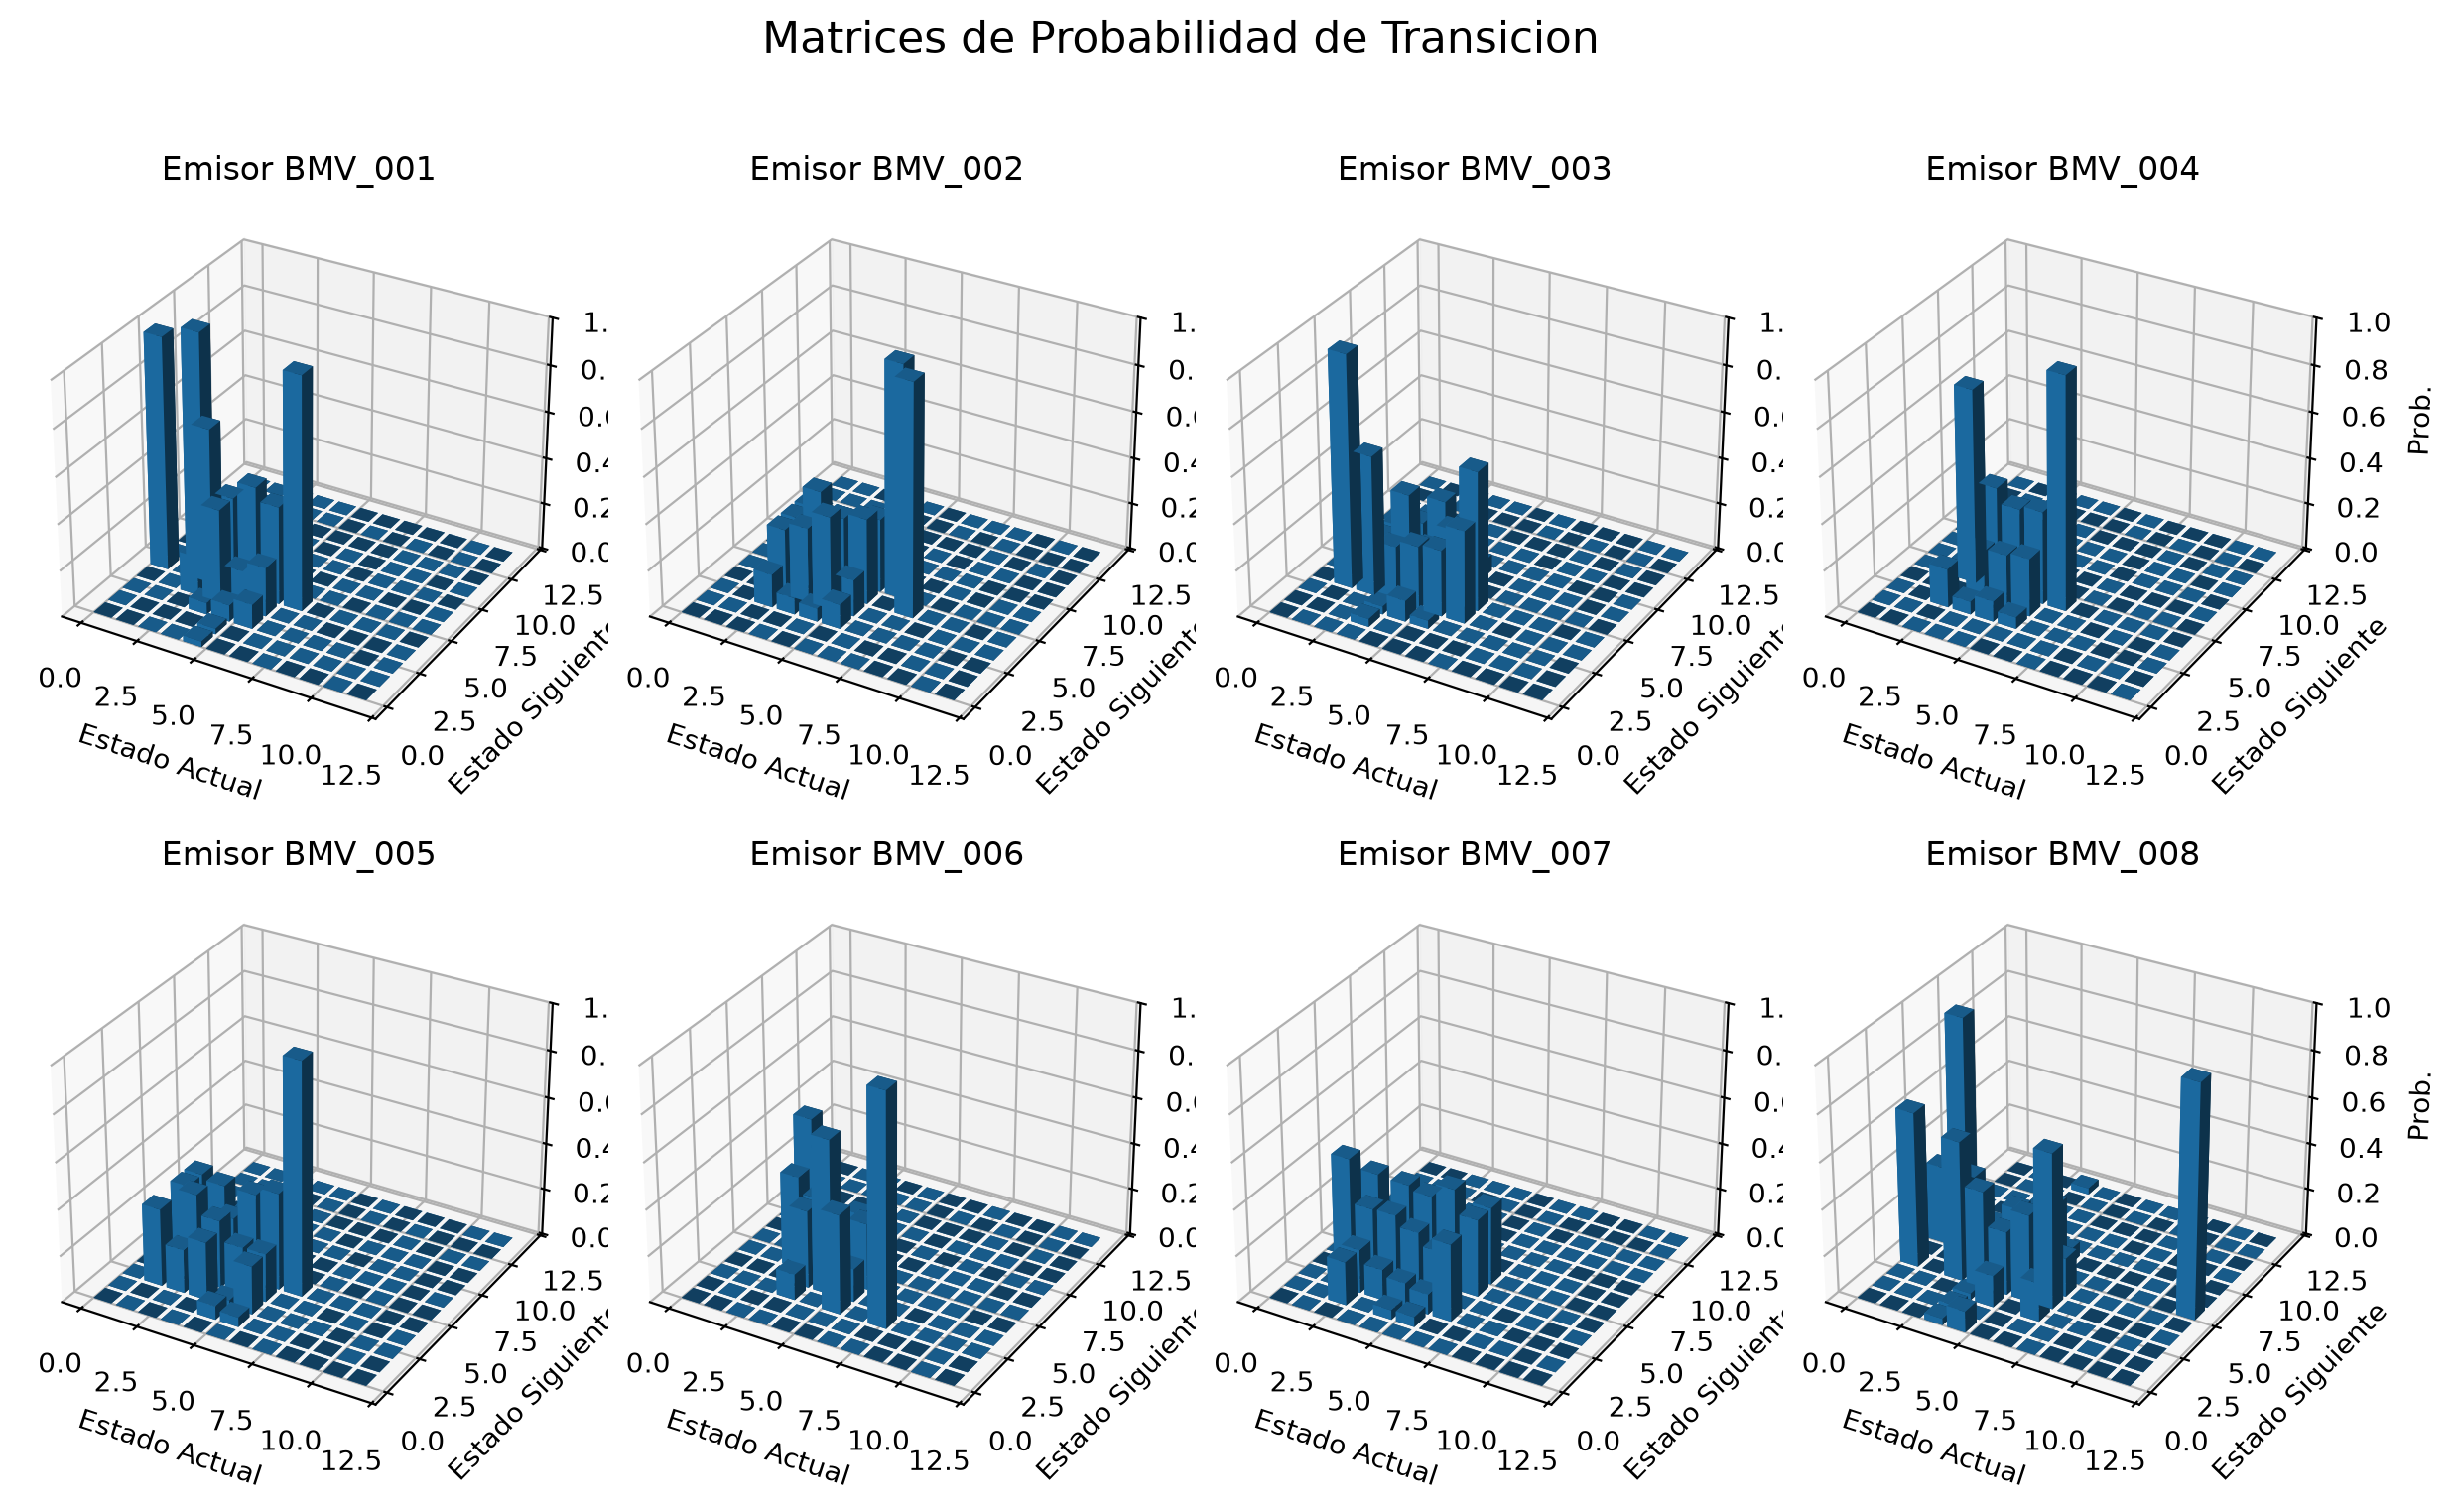

In [10]:
cuantos = len(emisores)
cols = 4
renglones = int(np.ceil(cuantos / cols))

fig, ejes = plt.subplots(renglones, cols, figsize=(12, 8),
                         subplot_kw={'projection': '3d'})
ejes = np.atleast_2d(ejes)

for k, emisor in enumerate(emisores):
    M = matrices[emisor]

    eje = ejes[k // cols, k % cols]

    ejeX = np.arange(M.shape[0])
    ejeY = np.arange(M.shape[1])
    X, Y = np.meshgrid(ejeX, ejeY)
    Z = M[X, Y]

    eje.bar3d(X.ravel(), Y.ravel(), np.zeros_like(Z).ravel(),
              0.8, 0.8, Z.ravel(), shade=True)

    eje.set_xlabel('Estado Actual')
    eje.set_ylabel('Estado Siguiente')
    eje.set_zlabel('Prob.')
    eje.set_title(f'Emisor {emisor}')
    eje.set_zlim(0, 1)

# Apaga ejes sobrantes
for j in range(cuantos, renglones * cols):
    ejes[j // cols, j % cols].axis('off')

fig.suptitle('Matrices de Probabilidad de Transicion', fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
def ultimaObservacion(emisor):
    hist = datos[datos['id_company'] == emisor]
    hist = hist.sort_values(by='date')
    calif = hist.iloc[-1]['rating']
    fecha = hist.iloc[-1]['date']
    print(f"Ultima calificacion el {fecha.strftime('%Y-%m-%d')} : {calif}")
    return calif, fecha


def siguienteCalif(emisor, calif_actual):
    M = matrices[emisor]
    fila = M[posicionDe(calif_actual)]
    destino = np.argmax(fila)
    return ESCALA[destino]


def siguienteFecha(fecha):
    # fecha es un Timestamp de pandas
    return fecha + pd.DateOffset(months=1)

In [12]:
def proyectar(mes_objetivo):
    for emisor in emisores:
        print(f"--EMISOR {emisor}--")
        calif, fecha = ultimaObservacion(emisor)
        while fecha < mes_objetivo:
            nueva_calif = siguienteCalif(emisor, calif)
            fecha = siguienteFecha(fecha)
            calif = nueva_calif

            print(f"Calificacion el {fecha.strftime('%Y-%m-%d')} : {nueva_calif} ")
        print("")


mes_objetivo = pd.Timestamp('2026-09-01')  # mes hasta el que se proyecta
proyectar(mes_objetivo)

--EMISOR BMV_001--
Ultima calificacion el 2026-08-01 : BB
Calificacion el 2026-09-01 : BB 

--EMISOR BMV_002--
Ultima calificacion el 2026-08-01 : B
Calificacion el 2026-09-01 : BB 

--EMISOR BMV_003--
Ultima calificacion el 2026-06-01 : BBB
Calificacion el 2026-07-01 : BB 
Calificacion el 2026-08-01 : B 
Calificacion el 2026-09-01 : BB 

--EMISOR BMV_004--
Ultima calificacion el 2026-08-01 : BB
Calificacion el 2026-09-01 : BB 

--EMISOR BMV_005--
Ultima calificacion el 2026-07-01 : BBB
Calificacion el 2026-08-01 : BBB 
Calificacion el 2026-09-01 : BBB 

--EMISOR BMV_006--
Ultima calificacion el 2026-08-01 : BBB
Calificacion el 2026-09-01 : BBB 

--EMISOR BMV_007--
Ultima calificacion el 2026-08-01 : BB
Calificacion el 2026-09-01 : BB 

--EMISOR BMV_008--
Ultima calificacion el 2026-08-01 : BBB
Calificacion el 2026-09-01 : BBB 

